In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import os
import gc
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import cv2
import nibabel as nib

import tensorflow as tf

from scipy.ndimage import binary_fill_holes
from scipy.spatial.distance import cdist


print("TensorFlow:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPU(s):", gpus)

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(
                gpu,
                True
            )

        print("✓ GPU memory growth enabled")

    except RuntimeError as e:
        print("GPU memory-growth warning:", e)

TensorFlow: 2.20.0
GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✓ GPU memory growth enabled


In [ ]:
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
    print("✓ TensorFlow deterministic operations enabled")

except Exception as e:
    print("Determinism note:", e)


print("Seed:", SEED)

✓ TensorFlow deterministic operations enabled
Seed: 42


In [ ]:
PROJECT_DIR = Path(
    "/content/drive/MyDrive/CAMUS_FINAL"
)

PHASE1_DIR = (
    PROJECT_DIR /
    "phase1_segmentation"
)

P1A_DIR = (
    PHASE1_DIR /
    "phase1A_resolution"
)

P1B_DIR = (
    PHASE1_DIR /
    "phase1B_hyperparameters"
)

P1B_CONFIG_DIR = (
    P1B_DIR /
    "configs"
)

P1B_MODEL_DIR = (
    P1B_DIR /
    "models"
)

P1B_HISTORY_DIR = (
    P1B_DIR /
    "histories"
)

P1B_TABLE_DIR = (
    P1B_DIR /
    "tables"
)

P1B_PLOT_DIR = (
    P1B_DIR /
    "plots"
)


for folder in [
    P1B_CONFIG_DIR,
    P1B_MODEL_DIR,
    P1B_HISTORY_DIR,
    P1B_TABLE_DIR,
    P1B_PLOT_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )


print("Project:")
print(PROJECT_DIR)

print("\nPhase 1B:")
print(P1B_DIR)

print("\n✓ Paths ready.")

Project:
/content/drive/MyDrive/CAMUS_FINAL

Phase 1B:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperparameters

✓ Paths ready.


In [ ]:
# ================================================================
# PHASE 1A — RESOLUTION
# ================================================================

RESOLUTION_DECISION_PATH = (
    P1A_DIR /
    "configs" /
    "phase1A_final_resolution_decision.json"
)

assert RESOLUTION_DECISION_PATH.exists()

with open(
    RESOLUTION_DECISION_PATH,
    "r"
) as f:
    resolution_decision = json.load(f)

SELECTED_RESOLUTION = int(
    resolution_decision[
        "selected_resolution"
    ]
)


# ================================================================
# PHASE 1B-1 — LEARNING RATE
# ================================================================

LR_DECISION_PATH = (
    P1B_CONFIG_DIR /
    "phase1B1_learning_rate_decision.json"
)

assert LR_DECISION_PATH.exists()

with open(
    LR_DECISION_PATH,
    "r"
) as f:
    lr_decision = json.load(f)

SELECTED_LEARNING_RATE = float(
    lr_decision[
        "selected_learning_rate"
    ]
)


# ================================================================
# PHASE 1B-2 — OPTIMIZER
# ================================================================

OPT_DECISION_PATH = (
    P1B_CONFIG_DIR /
    "phase1B2_optimizer_decision.json"
)

assert OPT_DECISION_PATH.exists()

with open(
    OPT_DECISION_PATH,
    "r"
) as f:
    optimizer_decision = json.load(f)

SELECTED_OPTIMIZER = (
    optimizer_decision[
        "selected_optimizer"
    ]
)


# ================================================================
# PHASE 1B-3 — BATCH SIZE
# ================================================================

BATCH_DECISION_PATH = (
    P1B_CONFIG_DIR /
    "phase1B3_batch_size_decision.json"
)

assert BATCH_DECISION_PATH.exists()

with open(
    BATCH_DECISION_PATH,
    "r"
) as f:
    batch_decision = json.load(f)

SELECTED_BATCH_SIZE = int(
    batch_decision[
        "selected_batch_size"
    ]
)


# ================================================================
# VERIFY
# ================================================================

assert SELECTED_RESOLUTION == 256

assert np.isclose(
    SELECTED_LEARNING_RATE,
    1e-4
)

assert SELECTED_OPTIMIZER == "Adam"

assert SELECTED_BATCH_SIZE == 2


print("LOCKED SETTINGS")

print(
    "Resolution    :",
    f"{SELECTED_RESOLUTION}×{SELECTED_RESOLUTION}"
)

print(
    "Learning rate :",
    SELECTED_LEARNING_RATE
)

print(
    "Optimizer     :",
    SELECTED_OPTIMIZER
)

print(
    "Batch size    :",
    SELECTED_BATCH_SIZE
)

print("\n✓ Previous decisions verified.")

LOCKED SETTINGS
Resolution    : 256×256
Learning rate : 0.0001
Optimizer     : Adam
Batch size    : 2

✓ Previous decisions verified.


In [ ]:
# CELL 6A — ONLY IF DATASET IS MISSING

import zipfile

OUTER_ZIP_PATH = Path(
    "/content/drive/MyDrive/download.zip"
)

OUTER_EXTRACT_DIR = Path(
    "/content/camus_data"
)

INNER_ARCHIVE_PATH = (
    OUTER_EXTRACT_DIR /
    "download"
)

INNER_EXTRACT_DIR = Path(
    "/content/camus_data_final"
)

DATASET_PATH = (
    INNER_EXTRACT_DIR /
    "database_nifti"
)


if not DATASET_PATH.exists():

    assert OUTER_ZIP_PATH.exists(), (
        f"Archive not found: {OUTER_ZIP_PATH}"
    )

    if not INNER_ARCHIVE_PATH.exists():

        print("Extracting outer archive...")

        OUTER_EXTRACT_DIR.mkdir(
            parents=True,
            exist_ok=True
        )

        with zipfile.ZipFile(
            OUTER_ZIP_PATH,
            "r"
        ) as archive:

            archive.extractall(
                OUTER_EXTRACT_DIR
            )

        print("✓ Outer archive extracted.")


    print("Extracting inner CAMUS archive...")

    INNER_EXTRACT_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    with zipfile.ZipFile(
        INNER_ARCHIVE_PATH,
        "r"
    ) as archive:

        archive.extractall(
            INNER_EXTRACT_DIR
        )


assert DATASET_PATH.exists()

print("\n✓ CAMUS dataset ready:")
print(DATASET_PATH)

Extracting outer archive...
✓ Outer archive extracted.
Extracting inner CAMUS archive...

✓ CAMUS dataset ready:
/content/camus_data_final/database_nifti


In [ ]:
SPLIT_PATH = (
    PROJECT_DIR /
    "splits" /
    "patient_split_seed42.json"
)

assert SPLIT_PATH.exists()


with open(
    SPLIT_PATH,
    "r"
) as f:
    patient_split = json.load(f)


train_ids = patient_split.get(
    "train_ids",
    patient_split.get("train")
)

val_ids = patient_split.get(
    "val_ids",
    patient_split.get(
        "validation",
        patient_split.get("val")
    )
)

test_ids = patient_split.get(
    "test_ids",
    patient_split.get("test")
)


assert len(train_ids) == 400
assert len(val_ids) == 50
assert len(test_ids) == 50

assert not (
    set(train_ids) & set(val_ids)
)

assert not (
    set(train_ids) & set(test_ids)
)

assert not (
    set(val_ids) & set(test_ids)
)


TRAIN_FRAMES = len(train_ids) * 2
VAL_FRAMES = len(val_ids) * 2


print("Train patients     :", len(train_ids))
print("Validation patients:", len(val_ids))
print("Test patients      :", len(test_ids))

print("Training frames    :", TRAIN_FRAMES)
print("Validation frames  :", VAL_FRAMES)

print("\n✓ Split verified.")
print("✓ Test set excluded from selection.")

Train patients     : 400
Validation patients: 50
Test patients      : 50
Training frames    : 800
Validation frames  : 100

✓ Split verified.
✓ Test set excluded from selection.


In [ ]:
BASELINE_PARAMETER_COUNT = 1_940_817

MAX_EPOCHS = 30
THRESHOLD = 0.50

AUGMENTATION_CONFIG = {

    "horizontal_flip_probability":
        0.50,

    "max_rotation_degrees":
        10.0,

    "max_translation_fraction":
        0.05,

    "brightness_delta":
        0.10,

    "contrast_lower":
        0.90,

    "contrast_upper":
        1.10
}


print("=" * 70)
print("PHASE 1B-4 — CONTROLLED AUGMENTATION EXPERIMENT")
print("=" * 70)


print("\nLOCKED SETTINGS")

print(
    "Resolution        :",
    f"{SELECTED_RESOLUTION}×{SELECTED_RESOLUTION}"
)

print(
    "Learning rate     :",
    SELECTED_LEARNING_RATE
)

print(
    "Optimizer         :",
    SELECTED_OPTIMIZER
)

print(
    "Batch size        :",
    SELECTED_BATCH_SIZE
)

print(
    "Architecture      : Baseline U-Net"
)

print(
    "Parameters        :",
    BASELINE_PARAMETER_COUNT
)

print(
    "Loss              : BCE + Dice"
)

print(
    "Epoch budget      :",
    MAX_EPOCHS
)

print(
    "Threshold         :",
    THRESHOLD
)


print("\nVARIABLE BEING TESTED")
print("Training augmentation")


print("\nEXPERIMENT ARMS")

print("1. No augmentation")

print(
    "2. Conservative augmentation"
)


print("\nAUGMENTATION POLICY")

for key, value in (
    AUGMENTATION_CONFIG.items()
):
    print(
        f"{key}: {value}"
    )


print("\nNOT USED")

print("Vertical flipping")
print("Elastic deformation")
print("Random cropping")
print("Large rotations")
print("Anatomy-distorting transformations")


print("\nDATA")

print(
    "Training frames     :",
    TRAIN_FRAMES
)

print(
    "Validation frames   :",
    VAL_FRAMES
)

print(
    "Test used for selection: NO"
)


print(
    "\n✓ Phase 1B-4 design frozen."
)

PHASE 1B-4 — CONTROLLED AUGMENTATION EXPERIMENT

LOCKED SETTINGS
Resolution        : 256×256
Learning rate     : 0.0001
Optimizer         : Adam
Batch size        : 2
Architecture      : Baseline U-Net
Parameters        : 1940817
Loss              : BCE + Dice
Epoch budget      : 30
Threshold         : 0.5

VARIABLE BEING TESTED
Training augmentation

EXPERIMENT ARMS
1. No augmentation
2. Conservative augmentation

AUGMENTATION POLICY
horizontal_flip_probability: 0.5
max_rotation_degrees: 10.0
max_translation_fraction: 0.05
brightness_delta: 0.1
contrast_lower: 0.9
contrast_upper: 1.1

NOT USED
Vertical flipping
Elastic deformation
Random cropping
Large rotations
Anatomy-distorting transformations

DATA
Training frames     : 800
Validation frames   : 100
Test used for selection: NO

✓ Phase 1B-4 design frozen.


In [ ]:
def load_nifti_2d(file_path):

    nii = nib.load(
        str(file_path)
    )

    data = np.asarray(
        nii.get_fdata(),
        dtype=np.float32
    )

    if (
        data.ndim == 3
        and data.shape[-1] == 1
    ):
        data = data[:, :, 0]

    if data.ndim != 2:
        raise ValueError(
            f"Expected 2D image, got {data.shape}"
        )

    return data


def load_camus_frame(
    patient_id,
    phase
):

    patient_dir = (
        DATASET_PATH /
        patient_id
    )

    image = load_nifti_2d(
        patient_dir /
        f"{patient_id}_4CH_{phase}.nii.gz"
    )

    full_mask = load_nifti_2d(
        patient_dir /
        f"{patient_id}_4CH_{phase}_gt.nii.gz"
    )

    lv_mask = (
        full_mask == 1
    ).astype(np.float32)

    return image, lv_mask


def preprocess_frame(
    image,
    mask,
    resolution=SELECTED_RESOLUTION
):

    image_resized = cv2.resize(
        image,
        (
            resolution,
            resolution
        ),
        interpolation=cv2.INTER_LINEAR
    )

    mask_resized = cv2.resize(
        mask,
        (
            resolution,
            resolution
        ),
        interpolation=cv2.INTER_NEAREST
    )

    lo = float(
        image_resized.min()
    )

    hi = float(
        image_resized.max()
    )

    if hi > lo:

        image_resized = (
            image_resized - lo
        ) / (
            hi - lo
        )

    else:

        image_resized = (
            np.zeros_like(
                image_resized,
                dtype=np.float32
            )
        )


    image_resized = (
        image_resized.astype(
            np.float32
        )
    )

    mask_resized = (
        mask_resized > 0.5
    ).astype(np.float32)


    return (
        image_resized[..., None],
        mask_resized[..., None]
    )


print("✓ Loading and preprocessing ready.")

✓ Loading and preprocessing ready.


In [ ]:
def apply_conservative_augmentation(
    image,
    mask,
    rng
):

    image = np.asarray(
        image[:, :, 0],
        dtype=np.float32
    )

    mask = np.asarray(
        mask[:, :, 0],
        dtype=np.float32
    )

    height, width = image.shape


    # ============================================================
    # 1. HORIZONTAL FLIP
    # ============================================================

    if rng.random() < (
        AUGMENTATION_CONFIG[
            "horizontal_flip_probability"
        ]
    ):

        image = np.fliplr(
            image
        ).copy()

        mask = np.fliplr(
            mask
        ).copy()


    # ============================================================
    # 2. SMALL ROTATION + TRANSLATION
    # ============================================================

    angle = rng.uniform(
        -AUGMENTATION_CONFIG[
            "max_rotation_degrees"
        ],
        AUGMENTATION_CONFIG[
            "max_rotation_degrees"
        ]
    )

    max_dx = (
        AUGMENTATION_CONFIG[
            "max_translation_fraction"
        ]
        * width
    )

    max_dy = (
        AUGMENTATION_CONFIG[
            "max_translation_fraction"
        ]
        * height
    )

    tx = rng.uniform(
        -max_dx,
        max_dx
    )

    ty = rng.uniform(
        -max_dy,
        max_dy
    )


    transform_matrix = (
        cv2.getRotationMatrix2D(
            (
                width / 2.0,
                height / 2.0
            ),
            angle,
            1.0
        )
    )

    transform_matrix[
        0, 2
    ] += tx

    transform_matrix[
        1, 2
    ] += ty


    image = cv2.warpAffine(
        image,
        transform_matrix,
        (
            width,
            height
        ),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )


    mask = cv2.warpAffine(
        mask,
        transform_matrix,
        (
            width,
            height
        ),
        flags=cv2.INTER_NEAREST,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )


    # ============================================================
    # 3. BRIGHTNESS
    # ============================================================

    brightness_change = rng.uniform(
        -AUGMENTATION_CONFIG[
            "brightness_delta"
        ],
        AUGMENTATION_CONFIG[
            "brightness_delta"
        ]
    )

    image = (
        image +
        brightness_change
    )


    # ============================================================
    # 4. CONTRAST
    # ============================================================

    contrast_factor = rng.uniform(
        AUGMENTATION_CONFIG[
            "contrast_lower"
        ],
        AUGMENTATION_CONFIG[
            "contrast_upper"
        ]
    )

    image_mean = float(
        image.mean()
    )

    image = (
        image_mean
        +
        contrast_factor
        * (
            image -
            image_mean
        )
    )


    image = np.clip(
        image,
        0.0,
        1.0
    ).astype(np.float32)


    mask = (
        mask > 0.5
    ).astype(np.float32)


    return (
        image[..., None],
        mask[..., None]
    )


print("✓ Conservative paired augmentation ready.")

✓ Conservative paired augmentation ready.


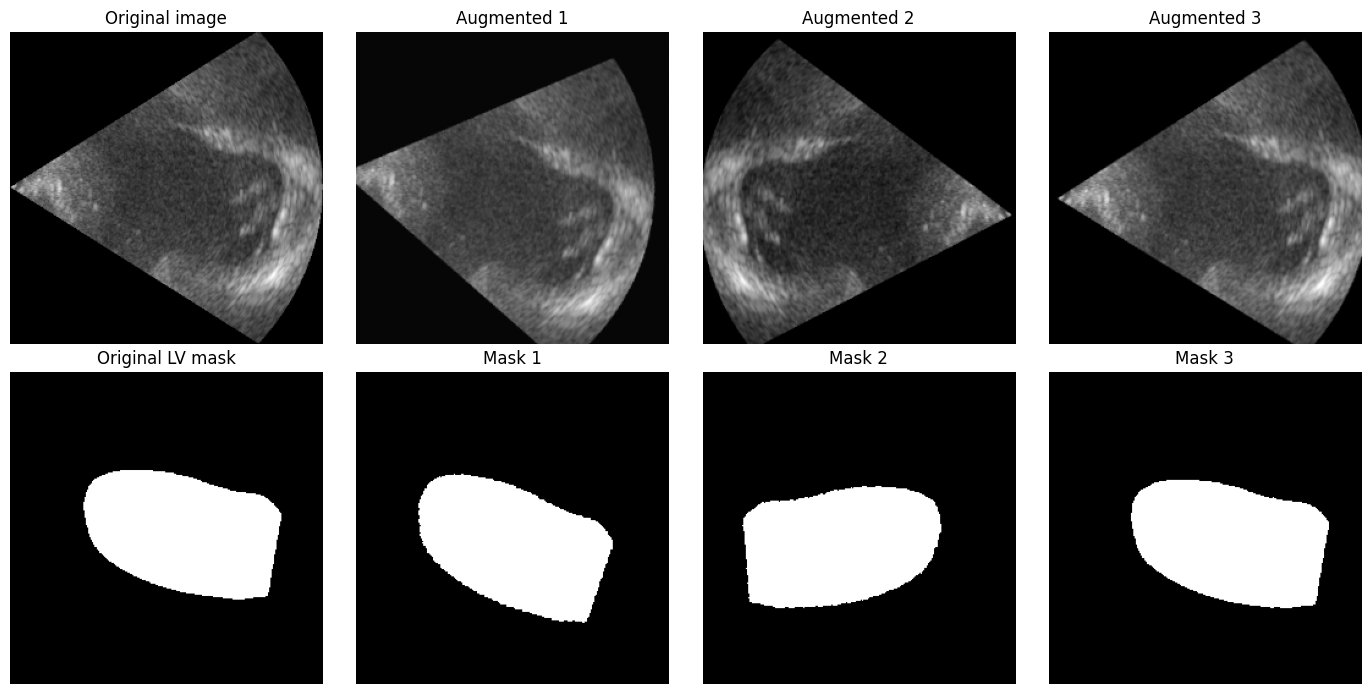

Original mask pixels: 13104

Visual check:
✓ LV mask should remain anatomically coherent.
✓ Image and mask geometry should remain aligned.
✓ No severe cropping or distortion should appear.


In [ ]:
sample_patient = train_ids[0]

sample_image_raw, sample_mask_raw = (
    load_camus_frame(
        sample_patient,
        "ED"
    )
)

sample_image, sample_mask = (
    preprocess_frame(
        sample_image_raw,
        sample_mask_raw
    )
)


fig, axes = plt.subplots(
    2,
    4,
    figsize=(14, 7)
)


# ------------------------------------------------
# Original
# ------------------------------------------------

axes[0, 0].imshow(
    sample_image[:, :, 0],
    cmap="gray"
)

axes[0, 0].set_title(
    "Original image"
)

axes[1, 0].imshow(
    sample_mask[:, :, 0],
    cmap="gray"
)

axes[1, 0].set_title(
    "Original LV mask"
)


# ------------------------------------------------
# Three deterministic augmentation examples
# ------------------------------------------------

for column in range(1, 4):

    preview_rng = (
        np.random.default_rng(
            SEED + column
        )
    )

    aug_image, aug_mask = (
        apply_conservative_augmentation(
            sample_image.copy(),
            sample_mask.copy(),
            preview_rng
        )
    )

    axes[0, column].imshow(
        aug_image[:, :, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[0, column].set_title(
        f"Augmented {column}"
    )

    axes[1, column].imshow(
        aug_mask[:, :, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[1, column].set_title(
        f"Mask {column}"
    )


for ax in axes.ravel():
    ax.axis("off")


plt.tight_layout()
plt.show()


print(
    "Original mask pixels:",
    int(sample_mask.sum())
)

print("\nVisual check:")
print(
    "✓ LV mask should remain anatomically coherent."
)
print(
    "✓ Image and mask geometry should remain aligned."
)
print(
    "✓ No severe cropping or distortion should appear."
)

In [ ]:
# ================================================================
# CHECK MANY AUGMENTATIONS BEFORE TRAINING
# ================================================================

augmentation_check_rng = (
    np.random.default_rng(
        SEED
    )
)

mask_pixel_counts = []

empty_masks = 0

for i in range(100):

    aug_image, aug_mask = (
        apply_conservative_augmentation(
            sample_image.copy(),
            sample_mask.copy(),
            augmentation_check_rng
        )
    )

    assert aug_image.shape == (
        256,
        256,
        1
    )

    assert aug_mask.shape == (
        256,
        256,
        1
    )

    assert np.isfinite(
        aug_image
    ).all()

    assert np.isfinite(
        aug_mask
    ).all()

    assert (
        aug_image.min() >= 0
    )

    assert (
        aug_image.max() <= 1
    )

    unique_mask_values = (
        np.unique(
            aug_mask
        )
    )

    assert set(
        unique_mask_values.tolist()
    ).issubset(
        {0.0, 1.0}
    )

    pixel_count = int(
        aug_mask.sum()
    )

    mask_pixel_counts.append(
        pixel_count
    )

    if pixel_count == 0:
        empty_masks += 1


print("100 augmentation checks completed.")

print(
    "Empty masks:",
    empty_masks
)

print(
    "Minimum augmented LV pixels:",
    min(mask_pixel_counts)
)

print(
    "Maximum augmented LV pixels:",
    max(mask_pixel_counts)
)

print(
    "Original LV pixels:",
    int(sample_mask.sum())
)


assert empty_masks == 0

print(
    "\n✓ Augmentation pipeline passed basic checks."
)

100 augmentation checks completed.
Empty masks: 0
Minimum augmented LV pixels: 13097
Maximum augmented LV pixels: 13109
Original LV pixels: 13104

✓ Augmentation pipeline passed basic checks.


In [ ]:
# ================================================================
# PHASE 1B-4 — CELL 13
# CONTROL vs AUGMENTED DATA GENERATORS
# ================================================================

def training_frame_generator(
    patient_ids,
    use_augmentation=False,
    seed=SEED
):

    frame_list = [
        (pid, phase)
        for pid in patient_ids
        for phase in ["ED", "ES"]
    ]

    # Controls frame ordering
    order_rng = np.random.default_rng(
        seed
    )

    # Separate RNG controls augmentation parameters
    augmentation_rng = np.random.default_rng(
        seed + 1000
    )

    while True:

        indices = np.arange(
            len(frame_list)
        )

        order_rng.shuffle(
            indices
        )

        for index in indices:

            pid, phase = (
                frame_list[index]
            )

            image, mask = (
                load_camus_frame(
                    pid,
                    phase
                )
            )

            x, y = preprocess_frame(
                image,
                mask
            )

            if use_augmentation:

                x, y = (
                    apply_conservative_augmentation(
                        x,
                        y,
                        augmentation_rng
                    )
                )

            yield (
                x.astype(np.float32),
                y.astype(np.float32)
            )


def validation_frame_generator(
    patient_ids
):

    frame_list = [
        (pid, phase)
        for pid in patient_ids
        for phase in ["ED", "ES"]
    ]

    while True:

        for pid, phase in frame_list:

            image, mask = (
                load_camus_frame(
                    pid,
                    phase
                )
            )

            x, y = preprocess_frame(
                image,
                mask
            )

            yield (
                x.astype(np.float32),
                y.astype(np.float32)
            )


OUTPUT_SIGNATURE = (

    tf.TensorSpec(
        shape=(
            SELECTED_RESOLUTION,
            SELECTED_RESOLUTION,
            1
        ),
        dtype=tf.float32
    ),

    tf.TensorSpec(
        shape=(
            SELECTED_RESOLUTION,
            SELECTED_RESOLUTION,
            1
        ),
        dtype=tf.float32
    )
)


def build_augmentation_experiment_datasets(
    use_augmentation
):

    training_dataset = (
        tf.data.Dataset
        .from_generator(
            lambda:
                training_frame_generator(
                    train_ids,
                    use_augmentation=
                        use_augmentation,
                    seed=SEED
                ),
            output_signature=
                OUTPUT_SIGNATURE
        )
        .batch(
            SELECTED_BATCH_SIZE,
            drop_remainder=True
        )
        .prefetch(1)
    )


    validation_dataset = (
        tf.data.Dataset
        .from_generator(
            lambda:
                validation_frame_generator(
                    val_ids
                ),
            output_signature=
                OUTPUT_SIGNATURE
        )
        .batch(
            SELECTED_BATCH_SIZE,
            drop_remainder=False
        )
        .prefetch(1)
    )


    train_steps = (
        TRAIN_FRAMES //
        SELECTED_BATCH_SIZE
    )

    validation_steps = int(
        np.ceil(
            VAL_FRAMES /
            SELECTED_BATCH_SIZE
        )
    )


    return (
        training_dataset,
        validation_dataset,
        train_steps,
        validation_steps
    )


print(
    "Training steps/epoch:",
    TRAIN_FRAMES // SELECTED_BATCH_SIZE
)

print(
    "Validation steps:",
    int(
        np.ceil(
            VAL_FRAMES /
            SELECTED_BATCH_SIZE
        )
    )
)

print("\n✓ Control and augmentation pipelines ready.")
print("✓ Validation augmentation: NONE.")

Training steps/epoch: 400
Validation steps: 50

✓ Control and augmentation pipelines ready.
✓ Validation augmentation: NONE.


In [ ]:
# ================================================================
# PHASE 1B-4 — CELL 14
# FIXED LOSS + METRICS
# ================================================================

SMOOTH = 1e-6


def dice_coefficient(
    y_true,
    y_pred
):

    y_true = tf.cast(
        y_true,
        tf.float32
    )

    y_pred = tf.cast(
        y_pred,
        tf.float32
    )

    intersection = tf.reduce_sum(
        y_true * y_pred,
        axis=[1, 2, 3]
    )

    denominator = (
        tf.reduce_sum(
            y_true,
            axis=[1, 2, 3]
        )
        +
        tf.reduce_sum(
            y_pred,
            axis=[1, 2, 3]
        )
    )

    dice = (
        2.0 * intersection + SMOOTH
    ) / (
        denominator + SMOOTH
    )

    return tf.reduce_mean(
        dice
    )


def iou_metric(
    y_true,
    y_pred
):

    y_true = tf.cast(
        y_true,
        tf.float32
    )

    y_pred = tf.cast(
        y_pred,
        tf.float32
    )

    intersection = tf.reduce_sum(
        y_true * y_pred,
        axis=[1, 2, 3]
    )

    union = (
        tf.reduce_sum(
            y_true,
            axis=[1, 2, 3]
        )
        +
        tf.reduce_sum(
            y_pred,
            axis=[1, 2, 3]
        )
        -
        intersection
    )

    iou = (
        intersection + SMOOTH
    ) / (
        union + SMOOTH
    )

    return tf.reduce_mean(
        iou
    )


def dice_loss(
    y_true,
    y_pred
):

    return (
        1.0 -
        dice_coefficient(
            y_true,
            y_pred
        )
    )


def bce_dice_loss(
    y_true,
    y_pred
):

    bce = (
        tf.keras.losses
        .binary_crossentropy(
            y_true,
            y_pred
        )
    )

    bce = tf.reduce_mean(
        bce
    )

    return (
        bce +
        dice_loss(
            y_true,
            y_pred
        )
    )


print("✓ BCE + Dice loss ready.")
print("✓ Dice and IoU metrics ready.")

✓ BCE + Dice loss ready.
✓ Dice and IoU metrics ready.


In [ ]:
# ================================================================
# PHASE 1B-4 — CELL 15
# FIXED BASELINE U-NET
# ================================================================

def conv_block(
    x,
    filters
):

    x = tf.keras.layers.Conv2D(
        filters,
        3,
        activation="relu",
        padding="same"
    )(x)

    x = tf.keras.layers.Conv2D(
        filters,
        3,
        activation="relu",
        padding="same"
    )(x)

    return x


def build_baseline_unet(
    input_shape=(256, 256, 1)
):

    inputs = tf.keras.Input(
        shape=input_shape
    )

    # Encoder
    c1 = conv_block(inputs, 16)
    p1 = tf.keras.layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 32)
    p2 = tf.keras.layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 64)
    p3 = tf.keras.layers.MaxPooling2D()(c3)

    c4 = conv_block(p3, 128)
    p4 = tf.keras.layers.MaxPooling2D()(c4)

    # Bottleneck
    c5 = conv_block(p4, 256)

    # Decoder
    u6 = tf.keras.layers.Conv2DTranspose(
        128,
        2,
        strides=2,
        padding="same"
    )(c5)

    u6 = tf.keras.layers.Concatenate()(
        [u6, c4]
    )

    c6 = conv_block(u6, 128)


    u7 = tf.keras.layers.Conv2DTranspose(
        64,
        2,
        strides=2,
        padding="same"
    )(c6)

    u7 = tf.keras.layers.Concatenate()(
        [u7, c3]
    )

    c7 = conv_block(u7, 64)


    u8 = tf.keras.layers.Conv2DTranspose(
        32,
        2,
        strides=2,
        padding="same"
    )(c7)

    u8 = tf.keras.layers.Concatenate()(
        [u8, c2]
    )

    c8 = conv_block(u8, 32)


    u9 = tf.keras.layers.Conv2DTranspose(
        16,
        2,
        strides=2,
        padding="same"
    )(c8)

    u9 = tf.keras.layers.Concatenate()(
        [u9, c1]
    )

    c9 = conv_block(u9, 16)


    outputs = tf.keras.layers.Conv2D(
        1,
        1,
        activation="sigmoid"
    )(c9)


    segmentation_model = (
        tf.keras.Model(
            inputs,
            outputs,
            name="Baseline_UNet"
        )
    )

    return segmentation_model


tf.keras.backend.clear_session()
gc.collect()

architecture_check_model = (
    build_baseline_unet(
        input_shape=(
            SELECTED_RESOLUTION,
            SELECTED_RESOLUTION,
            1
        )
    )
)

assert (
    architecture_check_model.count_params()
    ==
    BASELINE_PARAMETER_COUNT
)

print(
    "Parameter count:",
    architecture_check_model.count_params()
)

print("✓ Architecture verified.")

del architecture_check_model

tf.keras.backend.clear_session()
gc.collect()

Parameter count: 1940817
✓ Architecture verified.


0

In [ ]:
# ================================================================
# PHASE 1B-4 — CELL 16
# COMMON INITIALIZATION
# ================================================================

AUG_INITIAL_WEIGHTS_PATH = (
    P1B_CONFIG_DIR /
    "augmentation_experiment_initial_weights.weights.h5"
)


tf.keras.backend.clear_session()
gc.collect()

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


initialization_model = (
    build_baseline_unet(
        input_shape=(
            SELECTED_RESOLUTION,
            SELECTED_RESOLUTION,
            1
        )
    )
)


assert (
    initialization_model.count_params()
    ==
    BASELINE_PARAMETER_COUNT
)


initialization_model.save_weights(
    AUG_INITIAL_WEIGHTS_PATH
)


print("Common initialization saved:")
print(AUG_INITIAL_WEIGHTS_PATH)

print(
    "\nParameters:",
    initialization_model.count_params()
)


del initialization_model

tf.keras.backend.clear_session()
gc.collect()


print(
    "\n✓ Both augmentation arms will "
    "start from identical weights."
)

Common initialization saved:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperparameters/configs/augmentation_experiment_initial_weights.weights.h5

Parameters: 1940817

✓ Both augmentation arms will start from identical weights.


In [ ]:
# ================================================================
# PHASE 1B-4 — CELL 17
# SAVE FROZEN PROTOCOL
# ================================================================

augmentation_protocol = {

    "experiment":
        "Phase 1B-4 — Controlled Augmentation Experiment",

    "status":
        "PROTOCOL FROZEN BEFORE TRAINING",

    "variable_tested":
        "training_augmentation",

    "arms": [
        "No augmentation",
        "Conservative augmentation"
    ],

    "resolution":
        SELECTED_RESOLUTION,

    "learning_rate":
        SELECTED_LEARNING_RATE,

    "optimizer":
        SELECTED_OPTIMIZER,

    "batch_size":
        SELECTED_BATCH_SIZE,

    "architecture":
        "Baseline U-Net",

    "parameters":
        BASELINE_PARAMETER_COUNT,

    "loss":
        "BCE + Dice",

    "epochs":
        MAX_EPOCHS,

    "threshold":
        THRESHOLD,

    "seed":
        SEED,

    "augmentation_policy":
        AUGMENTATION_CONFIG,

    "validation_augmentation":
        False,

    "same_initial_weights":
        True,

    "same_training_frame_order":
        True,

    "train_frames_per_epoch":
        TRAIN_FRAMES,

    "validation_frames":
        VAL_FRAMES,

    "steps_per_epoch":
        TRAIN_FRAMES //
        SELECTED_BATCH_SIZE,

    "test_used":
        False
}


AUG_PROTOCOL_PATH = (
    P1B_CONFIG_DIR /
    "augmentation_experiment_protocol.json"
)


with open(
    AUG_PROTOCOL_PATH,
    "w"
) as f:

    json.dump(
        augmentation_protocol,
        f,
        indent=2
    )


print("=" * 70)
print("AUGMENTATION PROTOCOL FROZEN")
print("=" * 70)

print("\nControl:")
print("No augmentation")

print("\nExperimental:")
print("Conservative augmentation")

print("\nSame initialization: YES")
print("Same frame order: YES")
print("Validation augmented: NO")
print("Test used: NO")

print("\nSaved:")
print(AUG_PROTOCOL_PATH)

print("\n✓ Protocol frozen.")

AUGMENTATION PROTOCOL FROZEN

Control:
No augmentation

Experimental:
Conservative augmentation

Same initialization: YES
Same frame order: YES
Validation augmented: NO
Test used: NO

Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperparameters/configs/augmentation_experiment_protocol.json

✓ Protocol frozen.


In [ ]:
# ================================================================
# PHASE 1B-4 — CELL 18
# CONTROLLED TRAINING FUNCTION
# ================================================================

def train_augmentation_experiment(
    use_augmentation
):

    run_name = (
        "augmented"
        if use_augmentation
        else "no_augmentation"
    )

    display_name = (
        "CONSERVATIVE AUGMENTATION"
        if use_augmentation
        else "NO AUGMENTATION"
    )


    print("\n" + "=" * 70)
    print(
        f"TRAINING: {display_name}"
    )
    print("=" * 70)


    # ------------------------------------------------------------
    # Clean memory
    # ------------------------------------------------------------

    tf.keras.backend.clear_session()
    gc.collect()


    # ------------------------------------------------------------
    # Reset seeds
    # ------------------------------------------------------------

    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)


    # ------------------------------------------------------------
    # Dataset
    # ------------------------------------------------------------

    (
        training_dataset,
        validation_dataset,
        train_steps,
        validation_steps
    ) = build_augmentation_experiment_datasets(
        use_augmentation=
            use_augmentation
    )


    print(
        "Training steps/epoch:",
        train_steps
    )

    print(
        "Validation steps:",
        validation_steps
    )


    # ------------------------------------------------------------
    # Fresh model
    # ------------------------------------------------------------

    segmentation_model = (
        build_baseline_unet(
            input_shape=(
                SELECTED_RESOLUTION,
                SELECTED_RESOLUTION,
                1
            )
        )
    )


    segmentation_model.load_weights(
        AUG_INITIAL_WEIGHTS_PATH
    )


    assert (
        segmentation_model.count_params()
        ==
        BASELINE_PARAMETER_COUNT
    )


    # ------------------------------------------------------------
    # Fixed optimizer
    # ------------------------------------------------------------

    optimizer_instance = (
        tf.keras.optimizers.Adam(
            learning_rate=
                SELECTED_LEARNING_RATE
        )
    )


    segmentation_model.compile(
        optimizer=optimizer_instance,
        loss=bce_dice_loss,
        metrics=[
            dice_coefficient,
            iou_metric
        ]
    )


    # ------------------------------------------------------------
    # Paths
    # ------------------------------------------------------------

    model_path = (
        P1B_MODEL_DIR /
        f"augmentation_{run_name}_best.keras"
    )

    history_path = (
        P1B_HISTORY_DIR /
        f"augmentation_{run_name}_history.csv"
    )


    # ------------------------------------------------------------
    # Best validation Dice checkpoint
    # ------------------------------------------------------------

    checkpoint = (
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(
                model_path
            ),
            monitor=
                "val_dice_coefficient",
            mode="max",
            save_best_only=True,
            verbose=1
        )
    )


    # ------------------------------------------------------------
    # Train
    # ------------------------------------------------------------

    start_time = time.time()


    history = segmentation_model.fit(
        training_dataset,
        validation_data=
            validation_dataset,
        epochs=MAX_EPOCHS,
        steps_per_epoch=
            train_steps,
        validation_steps=
            validation_steps,
        callbacks=[
            checkpoint
        ],
        verbose=1
    )


    training_minutes = (
        time.time() -
        start_time
    ) / 60.0


    # ------------------------------------------------------------
    # Save history
    # ------------------------------------------------------------

    history_df = pd.DataFrame(
        history.history
    )

    history_df.index = (
        np.arange(
            len(history_df)
        ) + 1
    )

    history_df.index.name = "epoch"

    history_df.to_csv(
        history_path
    )


    # ------------------------------------------------------------
    # Best epoch
    # ------------------------------------------------------------

    val_dice_values = np.asarray(
        history.history[
            "val_dice_coefficient"
        ],
        dtype=float
    )


    best_index = int(
        np.argmax(
            val_dice_values
        )
    )


    result = {

        "augmentation":
            bool(
                use_augmentation
            ),

        "configuration":
            run_name,

        "parameters":
            int(
                segmentation_model.count_params()
            ),

        "batch_size":
            SELECTED_BATCH_SIZE,

        "best_epoch":
            int(
                best_index + 1
            ),

        "best_val_dice_training":
            float(
                val_dice_values[
                    best_index
                ]
            ),

        "val_iou_at_best_dice_epoch":
            float(
                history.history[
                    "val_iou_metric"
                ][best_index]
            ),

        "training_minutes":
            float(
                training_minutes
            ),

        "model_path":
            str(model_path),

        "history_path":
            str(history_path)
    }


    print("\n" + "-" * 70)

    print(
        f"{display_name} COMPLETE"
    )

    print(
        "Best epoch:",
        result["best_epoch"]
    )

    print(
        "Best validation Dice:",
        round(
            result[
                "best_val_dice_training"
            ],
            6
        )
    )

    print(
        "Validation IoU:",
        round(
            result[
                "val_iou_at_best_dice_epoch"
            ],
            6
        )
    )

    print(
        "Training time:",
        round(
            training_minutes,
            2
        ),
        "minutes"
    )

    print(
        "Checkpoint:",
        model_path
    )

    print("-" * 70)


    del segmentation_model
    del optimizer_instance
    del history
    del training_dataset
    del validation_dataset

    tf.keras.backend.clear_session()
    gc.collect()


    return result

In [ ]:
no_augmentation_result = (
    train_augmentation_experiment(
        False
    )
)

no_augmentation_result


TRAINING: NO AUGMENTATION
Training steps/epoch: 400
Validation steps: 50
Epoch 1/30
400/400 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - dice_coefficient: 0.2683 - iou_metric: 0.1692 - loss: 1.1394
Epoch 1: val_dice_coefficient improved from None to 0.72898, saving model to /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperparameters/models/augmentation_no_augmentation_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperparameters/models/augmentation_no_augmentation_best.keras
400/400 ━━━━━━━━━━━━━━━━━━━━ 37s 67ms/step - dice_coefficient: 0.4340 - iou_metric: 0.3009 - loss: 0.8232 - val_dice_coefficient: 0.7290 - val_iou_metric: 0.5783 - val_loss: 0.3932
Epoch 2/30
399/400 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - dice_coefficient: 0.7471 - iou_metric: 0.6055 - loss: 0.3715
Epoch 2: val_dice_coefficient improved from 0.72898 to 0.83560, saving model to /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperp

{'augmentation': False,
 'configuration': 'no_augmentation',
 'parameters': 1940817,
 'batch_size': 2,
 'best_epoch': 28,
 'best_val_dice_training': 0.9300199747085571,
 'val_iou_at_best_dice_epoch': 0.8713198900222778,
 'training_minutes': 12.68373061021169,
 'model_path': '/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperparameters/models/augmentation_no_augmentation_best.keras',
 'history_path': '/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperparameters/histories/augmentation_no_augmentation_history.csv'}

In [ ]:
augmentation_result = (
    train_augmentation_experiment(
        True
    )
)

augmentation_result


TRAINING: CONSERVATIVE AUGMENTATION
Training steps/epoch: 400
Validation steps: 50
Epoch 1/30
400/400 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - dice_coefficient: 0.2156 - iou_metric: 0.1274 - loss: 1.2126
Epoch 1: val_dice_coefficient improved from None to 0.66889, saving model to /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperparameters/models/augmentation_augmented_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperparameters/models/augmentation_augmented_best.keras
400/400 ━━━━━━━━━━━━━━━━━━━━ 29s 59ms/step - dice_coefficient: 0.3353 - iou_metric: 0.2168 - loss: 0.9488 - val_dice_coefficient: 0.6689 - val_iou_metric: 0.5080 - val_loss: 0.4457
Epoch 2/30
400/400 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - dice_coefficient: 0.6718 - iou_metric: 0.5189 - loss: 0.4724
Epoch 2: val_dice_coefficient improved from 0.66889 to 0.75255, saving model to /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperpar

{'augmentation': True,
 'configuration': 'augmented',
 'parameters': 1940817,
 'batch_size': 2,
 'best_epoch': 30,
 'best_val_dice_training': 0.9182319045066833,
 'val_iou_at_best_dice_epoch': 0.8523213863372803,
 'training_minutes': 12.886142313480377,
 'model_path': '/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperparameters/models/augmentation_augmented_best.keras',
 'history_path': '/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperparameters/histories/augmentation_augmented_history.csv'}

In [ ]:
# ================================================================
# PHASE 1B-4 — CELL 21
# TRAINING SUMMARY
# ================================================================

augmentation_training_summary = (
    pd.DataFrame([
        no_augmentation_result,
        augmentation_result
    ])
)


AUG_TRAINING_SUMMARY_PATH = (
    P1B_TABLE_DIR /
    "augmentation_training_summary.csv"
)


augmentation_training_summary.to_csv(
    AUG_TRAINING_SUMMARY_PATH,
    index=False
)


display(
    augmentation_training_summary[
        [
            "configuration",
            "augmentation",
            "parameters",
            "batch_size",
            "best_epoch",
            "best_val_dice_training",
            "val_iou_at_best_dice_epoch",
            "training_minutes"
        ]
    ].round(6)
)


print("\n✓ Training summary saved:")
print(AUG_TRAINING_SUMMARY_PATH)

,configuration,augmentation,parameters,batch_size,best_epoch,best_val_dice_training,val_iou_at_best_dice_epoch,training_minutes
0,no_augmentation,False,1940817,2,28,0.930020,0.871320,12.683731
1,augmented,True,1940817,2,30,0.918232,0.852321,12.886142



✓ Training summary saved:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperparameters/tables/augmentation_training_summary.csv


In [ ]:
# ================================================================
# PHASE 1B-4 — CELL 22
# POSTPROCESSING + VALIDATION METRICS
# ================================================================

def keep_largest_component(mask):

    mask = np.asarray(mask).astype(np.uint8)

    if mask.sum() == 0:
        return np.zeros_like(mask, dtype=bool)

    n_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            mask,
            connectivity=8
        )
    )

    if n_labels <= 1:
        return np.zeros_like(mask, dtype=bool)

    largest_label = (
        1 +
        np.argmax(
            stats[1:, cv2.CC_STAT_AREA]
        )
    )

    return labels == largest_label


def postprocess_prediction(mask):

    largest = keep_largest_component(mask)

    filled = binary_fill_holes(
        largest
    )

    return np.asarray(
        filled,
        dtype=bool
    )


def binary_dice(gt, pred):

    gt = np.asarray(gt).astype(bool)
    pred = np.asarray(pred).astype(bool)

    intersection = np.logical_and(
        gt, pred
    ).sum()

    denominator = (
        gt.sum() + pred.sum()
    )

    if denominator == 0:
        return 1.0

    return (
        2.0 * intersection /
        denominator
    )


def binary_iou(gt, pred):

    gt = np.asarray(gt).astype(bool)
    pred = np.asarray(pred).astype(bool)

    intersection = np.logical_and(
        gt, pred
    ).sum()

    union = np.logical_or(
        gt, pred
    ).sum()

    if union == 0:
        return 1.0

    return intersection / union


def binary_precision(gt, pred):

    gt = np.asarray(gt).astype(bool)
    pred = np.asarray(pred).astype(bool)

    tp = np.logical_and(
        gt, pred
    ).sum()

    fp = np.logical_and(
        ~gt, pred
    ).sum()

    if (tp + fp) == 0:
        return (
            1.0
            if gt.sum() == 0
            else 0.0
        )

    return tp / (tp + fp)


def binary_recall(gt, pred):

    gt = np.asarray(gt).astype(bool)
    pred = np.asarray(pred).astype(bool)

    tp = np.logical_and(
        gt, pred
    ).sum()

    fn = np.logical_and(
        gt, ~pred
    ).sum()

    if (tp + fn) == 0:
        return 1.0

    return tp / (tp + fn)


def boundary_points(mask):

    mask = np.asarray(
        mask
    ).astype(np.uint8)

    kernel = np.ones(
        (3, 3),
        dtype=np.uint8
    )

    eroded = cv2.erode(
        mask,
        kernel,
        iterations=1
    )

    boundary = (
        mask.astype(bool)
        &
        ~eroded.astype(bool)
    )

    return np.column_stack(
        np.where(boundary)
    )


def hd95_pixels(gt, pred):

    gt_points = boundary_points(gt)
    pred_points = boundary_points(pred)

    if (
        len(gt_points) == 0
        or len(pred_points) == 0
    ):
        return np.nan

    distances = cdist(
        gt_points,
        pred_points
    )

    gt_to_pred = distances.min(
        axis=1
    )

    pred_to_gt = distances.min(
        axis=0
    )

    all_distances = np.concatenate([
        gt_to_pred,
        pred_to_gt
    ])

    return float(
        np.percentile(
            all_distances,
            95
        )
    )


print("✓ Postprocessing and metrics ready.")

✓ Postprocessing and metrics ready.


In [ ]:
# ================================================================
# PHASE 1B-4 — CELL 23
# AUGMENTATION CHECKPOINT EVALUATOR
# ================================================================

def evaluate_augmentation_checkpoint(
    configuration
):

    assert configuration in [
        "no_augmentation",
        "augmented"
    ]

    model_path = (
        P1B_MODEL_DIR /
        f"augmentation_{configuration}_best.keras"
    )

    assert model_path.exists(), (
        f"Checkpoint missing:\n{model_path}"
    )


    print("\n" + "=" * 70)
    print(
        f"EVALUATING: {configuration.upper()}"
    )
    print("=" * 70)


    tf.keras.backend.clear_session()
    gc.collect()


    evaluation_model = (
        tf.keras.models.load_model(
            model_path,
            custom_objects={
                "bce_dice_loss":
                    bce_dice_loss,

                "dice_coefficient":
                    dice_coefficient,

                "iou_metric":
                    iou_metric
            }
        )
    )


    records = []


    for patient_number, pid in enumerate(
        val_ids,
        start=1
    ):

        for phase in ["ED", "ES"]:

            image, gt_mask = (
                load_camus_frame(
                    pid,
                    phase
                )
            )

            x, gt_resized = (
                preprocess_frame(
                    image,
                    gt_mask
                )
            )


            probability = (
                evaluation_model(
                    x[None, ...],
                    training=False
                )
                .numpy()[0, :, :, 0]
            )


            pred_raw = (
                probability >= THRESHOLD
            )


            pred_mask = (
                postprocess_prediction(
                    pred_raw
                )
            )


            gt_binary = (
                gt_resized[:, :, 0]
                > 0.5
            )


            gt_area = int(
                gt_binary.sum()
            )

            pred_area = int(
                pred_mask.sum()
            )


            if gt_area > 0:

                signed_area_error_pct = (
                    (pred_area - gt_area)
                    / gt_area
                    * 100.0
                )

                abs_area_error_pct = abs(
                    signed_area_error_pct
                )

            else:

                signed_area_error_pct = np.nan
                abs_area_error_pct = np.nan


            hd95 = hd95_pixels(
                gt_binary,
                pred_mask
            )


            records.append({

                "patient_id":
                    pid,

                "phase":
                    phase,

                "configuration":
                    configuration,

                "dice":
                    binary_dice(
                        gt_binary,
                        pred_mask
                    ),

                "iou":
                    binary_iou(
                        gt_binary,
                        pred_mask
                    ),

                "precision":
                    binary_precision(
                        gt_binary,
                        pred_mask
                    ),

                "recall":
                    binary_recall(
                        gt_binary,
                        pred_mask
                    ),

                "hd95_pixels":
                    hd95,

                "normalized_hd95":
                    (
                        hd95 /
                        SELECTED_RESOLUTION
                        if np.isfinite(hd95)
                        else np.nan
                    ),

                "gt_area_pixels":
                    gt_area,

                "pred_area_pixels":
                    pred_area,

                "signed_area_error_pct":
                    signed_area_error_pct,

                "abs_area_error_pct":
                    abs_area_error_pct
            })


        if patient_number % 10 == 0:

            print(
                f"Evaluated "
                f"{patient_number}/"
                f"{len(val_ids)} patients"
            )


    results_df = pd.DataFrame(
        records
    )


    assert len(results_df) == 100


    output_path = (
        P1B_TABLE_DIR /
        f"augmentation_{configuration}_validation_metrics.csv"
    )


    results_df.to_csv(
        output_path,
        index=False
    )


    print(
        "\nFrames evaluated:",
        len(results_df)
    )

    print("Saved:")
    print(output_path)


    del evaluation_model

    tf.keras.backend.clear_session()
    gc.collect()


    return results_df

In [ ]:
# ================================================================
# PHASE 1B-4 — CELL 24
# EVALUATE BOTH CHECKPOINTS
# ================================================================

no_augmentation_eval = (
    evaluate_augmentation_checkpoint(
        "no_augmentation"
    )
)


augmented_eval = (
    evaluate_augmentation_checkpoint(
        "augmented"
    )
)


assert len(
    no_augmentation_eval
) == 100

assert len(
    augmented_eval
) == 100


print(
    "\n✓ Both checkpoints evaluated "
    "on the same 100 validation frames."
)

print(
    "✓ Validation images were NOT augmented."
)

print(
    "✓ Test set was NOT used."
)


EVALUATING: NO_AUGMENTATION
Evaluated 10/50 patients
Evaluated 20/50 patients
Evaluated 30/50 patients
Evaluated 40/50 patients
Evaluated 50/50 patients

Frames evaluated: 100
Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperparameters/tables/augmentation_no_augmentation_validation_metrics.csv

EVALUATING: AUGMENTED
Evaluated 10/50 patients
Evaluated 20/50 patients
Evaluated 30/50 patients
Evaluated 40/50 patients
Evaluated 50/50 patients

Frames evaluated: 100
Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperparameters/tables/augmentation_augmented_validation_metrics.csv

✓ Both checkpoints evaluated on the same 100 validation frames.
✓ Validation images were NOT augmented.
✓ Test set was NOT used.


In [ ]:
# ================================================================
# PHASE 1B-4 — CELL 25
# FINAL AUGMENTATION COMPARISON
# ================================================================

def summarize_augmentation_results(
    evaluation_df,
    training_result
):

    ed = evaluation_df[
        evaluation_df["phase"] == "ED"
    ]

    es = evaluation_df[
        evaluation_df["phase"] == "ES"
    ]


    return {

        "configuration":
            training_result[
                "configuration"
            ],

        "augmentation":
            training_result[
                "augmentation"
            ],

        "parameters":
            training_result[
                "parameters"
            ],

        "batch_size":
            training_result[
                "batch_size"
            ],

        "best_epoch":
            training_result[
                "best_epoch"
            ],

        "training_minutes":
            training_result[
                "training_minutes"
            ],

        "overall_dice":
            evaluation_df[
                "dice"
            ].mean(),

        "ED_dice":
            ed[
                "dice"
            ].mean(),

        "ES_dice":
            es[
                "dice"
            ].mean(),

        "overall_iou":
            evaluation_df[
                "iou"
            ].mean(),

        "precision":
            evaluation_df[
                "precision"
            ].mean(),

        "recall":
            evaluation_df[
                "recall"
            ].mean(),

        "normalized_hd95":
            evaluation_df[
                "normalized_hd95"
            ].mean(),

        "ED_area_MAE_pct":
            ed[
                "abs_area_error_pct"
            ].mean(),

        "ES_area_MAE_pct":
            es[
                "abs_area_error_pct"
            ].mean(),

        "overall_area_MAE_pct":
            evaluation_df[
                "abs_area_error_pct"
            ].mean(),

        "ED_signed_area_error_pct":
            ed[
                "signed_area_error_pct"
            ].mean(),

        "ES_signed_area_error_pct":
            es[
                "signed_area_error_pct"
            ].mean(),

        "overall_signed_area_error_pct":
            evaluation_df[
                "signed_area_error_pct"
            ].mean()
    }


augmentation_comparison = (
    pd.DataFrame([

        summarize_augmentation_results(
            no_augmentation_eval,
            no_augmentation_result
        ),

        summarize_augmentation_results(
            augmented_eval,
            augmentation_result
        )

    ])
)


AUG_COMPARISON_PATH = (
    P1B_TABLE_DIR /
    "augmentation_validation_comparison.csv"
)


augmentation_comparison.to_csv(
    AUG_COMPARISON_PATH,
    index=False
)


display(
    augmentation_comparison.round(4)
)


print(
    "\n✓ Final augmentation comparison saved:"
)

print(
    AUG_COMPARISON_PATH
)

,configuration,augmentation,parameters,batch_size,best_epoch,training_minutes,overall_dice,ED_dice,ES_dice,overall_iou,precision,recall,normalized_hd95,ED_area_MAE_pct,ES_area_MAE_pct,overall_area_MAE_pct,ED_signed_area_error_pct,ES_signed_area_error_pct,overall_signed_area_error_pct
0,no_augmentation,False,1940817,2,28,12.6837,0.9335,0.9435,0.9234,0.8774,0.9348,0.9378,0.0226,6.314,10.3131,8.3135,0.4121,2.1079,1.2600
1,augmented,True,1940817,2,30,12.8861,0.9265,0.9403,0.9126,0.8666,0.9131,0.9478,0.0253,6.570,14.1300,10.3500,2.0853,8.6959,5.3906



✓ Final augmentation comparison saved:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperparameters/tables/augmentation_validation_comparison.csv


In [ ]:
# ================================================================
# PHASE 1B-4 — CELL 26
# PAIRED FRAME-LEVEL DIFFERENCES
# ================================================================

assert (
    no_augmentation_eval[
        ["patient_id", "phase"]
    ]
    .reset_index(drop=True)
    .equals(
        augmented_eval[
            ["patient_id", "phase"]
        ]
        .reset_index(drop=True)
    )
)


paired_difference = pd.DataFrame({

    "patient_id":
        no_augmentation_eval[
            "patient_id"
        ].values,

    "phase":
        no_augmentation_eval[
            "phase"
        ].values,

    "dice_change_aug_minus_control":
        (
            augmented_eval["dice"].values
            -
            no_augmentation_eval["dice"].values
        ),

    "iou_change_aug_minus_control":
        (
            augmented_eval["iou"].values
            -
            no_augmentation_eval["iou"].values
        ),

    "hd95_change_aug_minus_control":
        (
            augmented_eval[
                "normalized_hd95"
            ].values
            -
            no_augmentation_eval[
                "normalized_hd95"
            ].values
        ),

    "area_MAE_change_aug_minus_control":
        (
            augmented_eval[
                "abs_area_error_pct"
            ].values
            -
            no_augmentation_eval[
                "abs_area_error_pct"
            ].values
        )
})


PAIRED_DIFF_PATH = (
    P1B_TABLE_DIR /
    "augmentation_paired_frame_differences.csv"
)

paired_difference.to_csv(
    PAIRED_DIFF_PATH,
    index=False
)


paired_summary = pd.DataFrame({

    "metric": [
        "Dice",
        "IoU",
        "Normalized HD95",
        "Area MAE %"
    ],

    "mean_change_aug_minus_control": [

        paired_difference[
            "dice_change_aug_minus_control"
        ].mean(),

        paired_difference[
            "iou_change_aug_minus_control"
        ].mean(),

        paired_difference[
            "hd95_change_aug_minus_control"
        ].mean(),

        paired_difference[
            "area_MAE_change_aug_minus_control"
        ].mean()
    ]
})


display(
    paired_summary.round(6)
)


dice_improved = int(
    (
        paired_difference[
            "dice_change_aug_minus_control"
        ] > 0
    ).sum()
)

dice_worsened = int(
    (
        paired_difference[
            "dice_change_aug_minus_control"
        ] < 0
    ).sum()
)


print(
    f"\nFrames with improved Dice: "
    f"{dice_improved}/100"
)

print(
    f"Frames with worsened Dice: "
    f"{dice_worsened}/100"
)

print("\nSaved:")
print(PAIRED_DIFF_PATH)

,metric,mean_change_aug_minus_control
0,Dice,-0.007002
1,IoU,-0.010811
2,Normalized HD95,0.002697
3,Area MAE %,2.036446



Frames with improved Dice: 44/100
Frames with worsened Dice: 56/100

Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperparameters/tables/augmentation_paired_frame_differences.csv


In [ ]:
# ================================================================
# PHASE 1B-4 — CELL 27
# FINAL AUGMENTATION DECISION
# ================================================================

SELECTED_AUGMENTATION = False
SELECTED_AUGMENTATION_NAME = "No augmentation"

selected_row = augmentation_comparison[
    augmentation_comparison["configuration"] == "no_augmentation"
].iloc[0]

augmented_row = augmentation_comparison[
    augmentation_comparison["configuration"] == "augmented"
].iloc[0]


augmentation_decision = {

    "experiment":
        "Phase 1B-4 — Controlled Augmentation Experiment",

    "status":
        "COMPLETED",

    "selected_augmentation":
        SELECTED_AUGMENTATION,

    "selected_configuration":
        "no_augmentation",

    "augmentation_policy_tested":
        AUGMENTATION_CONFIG,

    # ------------------------------------------------------------
    # LOCKED SETTINGS
    # ------------------------------------------------------------

    "fixed_resolution":
        SELECTED_RESOLUTION,

    "fixed_learning_rate":
        SELECTED_LEARNING_RATE,

    "fixed_optimizer":
        SELECTED_OPTIMIZER,

    "fixed_batch_size":
        SELECTED_BATCH_SIZE,

    "fixed_architecture":
        "Baseline U-Net",

    "parameter_count":
        BASELINE_PARAMETER_COUNT,

    "fixed_loss":
        "BCE + Dice",

    "epochs":
        MAX_EPOCHS,

    "threshold":
        THRESHOLD,

    "seed":
        SEED,

    # ------------------------------------------------------------
    # DATA USAGE
    # ------------------------------------------------------------

    "selection_dataset":
        "Validation set only",

    "validation_frames":
        VAL_FRAMES,

    "test_set_used":
        False,

    # ------------------------------------------------------------
    # SELECTED RESULTS
    # ------------------------------------------------------------

    "selected_validation_results": {

        "overall_dice":
            float(
                selected_row["overall_dice"]
            ),

        "ED_dice":
            float(
                selected_row["ED_dice"]
            ),

        "ES_dice":
            float(
                selected_row["ES_dice"]
            ),

        "overall_iou":
            float(
                selected_row["overall_iou"]
            ),

        "precision":
            float(
                selected_row["precision"]
            ),

        "recall":
            float(
                selected_row["recall"]
            ),

        "normalized_hd95":
            float(
                selected_row["normalized_hd95"]
            ),

        "ED_area_MAE_pct":
            float(
                selected_row["ED_area_MAE_pct"]
            ),

        "ES_area_MAE_pct":
            float(
                selected_row["ES_area_MAE_pct"]
            ),

        "overall_area_MAE_pct":
            float(
                selected_row["overall_area_MAE_pct"]
            ),

        "ED_signed_area_error_pct":
            float(
                selected_row[
                    "ED_signed_area_error_pct"
                ]
            ),

        "ES_signed_area_error_pct":
            float(
                selected_row[
                    "ES_signed_area_error_pct"
                ]
            ),

        "overall_signed_area_error_pct":
            float(
                selected_row[
                    "overall_signed_area_error_pct"
                ]
            )
    },

    # ------------------------------------------------------------
    # AUGMENTED RESULTS
    # ------------------------------------------------------------

    "augmented_validation_results": {

        "overall_dice":
            float(
                augmented_row["overall_dice"]
            ),

        "ED_dice":
            float(
                augmented_row["ED_dice"]
            ),

        "ES_dice":
            float(
                augmented_row["ES_dice"]
            ),

        "overall_iou":
            float(
                augmented_row["overall_iou"]
            ),

        "normalized_hd95":
            float(
                augmented_row["normalized_hd95"]
            ),

        "ED_area_MAE_pct":
            float(
                augmented_row["ED_area_MAE_pct"]
            ),

        "ES_area_MAE_pct":
            float(
                augmented_row["ES_area_MAE_pct"]
            ),

        "overall_area_MAE_pct":
            float(
                augmented_row[
                    "overall_area_MAE_pct"
                ]
            )
    },

    # ------------------------------------------------------------
    # PAIRED DIFFERENCES
    # ------------------------------------------------------------

    "paired_mean_change_aug_minus_control": {

        "dice":
            float(
                paired_difference[
                    "dice_change_aug_minus_control"
                ].mean()
            ),

        "iou":
            float(
                paired_difference[
                    "iou_change_aug_minus_control"
                ].mean()
            ),

        "normalized_hd95":
            float(
                paired_difference[
                    "hd95_change_aug_minus_control"
                ].mean()
            ),

        "area_MAE_pct":
            float(
                paired_difference[
                    "area_MAE_change_aug_minus_control"
                ].mean()
            )
    },

    "frames_with_improved_dice":
        int(dice_improved),

    "frames_with_worsened_dice":
        int(dice_worsened),

    # ------------------------------------------------------------
    # DECISION
    # ------------------------------------------------------------

    "selection_reason": (
        "No augmentation was selected because it produced stronger "
        "validation performance than the predefined conservative "
        "augmentation policy. The no-augmentation model achieved "
        "higher overall, ED, and ES Dice; higher IoU; lower normalized "
        "HD95; and substantially lower LV area error, particularly at "
        "end-systole. Although the augmented model achieved higher "
        "recall, this was accompanied by lower precision and increased "
        "positive area bias. Paired frame-level analysis also showed "
        "negative mean changes in Dice and IoU and increased HD95 and "
        "area MAE under augmentation."
    ),

    "interpretation_note": (
        "This result applies specifically to the conservative "
        "augmentation policy tested in this controlled experiment. "
        "It does not establish that all possible augmentation "
        "strategies are harmful for CAMUS LV segmentation."
    ),

    "next_experiment":
        "Phase 1C — Controlled Model Capacity Experiment"
}


AUG_DECISION_PATH = (
    P1B_CONFIG_DIR /
    "phase1B4_augmentation_decision.json"
)


with open(
    AUG_DECISION_PATH,
    "w"
) as f:

    json.dump(
        augmentation_decision,
        f,
        indent=2
    )


print("=" * 70)
print("PHASE 1B-4 COMPLETED")
print("=" * 70)

print("\nSELECTED:")
print("No augmentation")

print("\nSELECTED VALIDATION RESULTS")
print(
    f"Overall Dice     : "
    f"{selected_row['overall_dice']:.4f}"
)
print(
    f"ED Dice          : "
    f"{selected_row['ED_dice']:.4f}"
)
print(
    f"ES Dice          : "
    f"{selected_row['ES_dice']:.4f}"
)
print(
    f"Overall IoU      : "
    f"{selected_row['overall_iou']:.4f}"
)
print(
    f"Normalized HD95  : "
    f"{selected_row['normalized_hd95']:.4f}"
)
print(
    f"ED Area MAE      : "
    f"{selected_row['ED_area_MAE_pct']:.2f}%"
)
print(
    f"ES Area MAE      : "
    f"{selected_row['ES_area_MAE_pct']:.2f}%"
)
print(
    f"Overall Area MAE : "
    f"{selected_row['overall_area_MAE_pct']:.2f}%"
)

print("\nTEST SET USED: NO")

print("\nCURRENT LOCKED PIPELINE")
print(
    f"Resolution   : "
    f"{SELECTED_RESOLUTION}×{SELECTED_RESOLUTION}"
)
print(
    f"LR           : "
    f"{SELECTED_LEARNING_RATE}"
)
print(
    f"Optimizer    : "
    f"{SELECTED_OPTIMIZER}"
)
print(
    f"Batch size   : "
    f"{SELECTED_BATCH_SIZE}"
)
print(
    "Augmentation : None"
)
print(
    "Loss         : BCE + Dice"
)

print("\nDecision saved:")
print(AUG_DECISION_PATH)

print("\nNEXT:")
print("Phase 1C — Controlled Model Capacity Experiment")

print("\n✓ Phase 1B is now complete.")

PHASE 1B-4 COMPLETED

SELECTED:
No augmentation

SELECTED VALIDATION RESULTS
Overall Dice     : 0.9335
ED Dice          : 0.9435
ES Dice          : 0.9234
Overall IoU      : 0.8774
Normalized HD95  : 0.0226
ED Area MAE      : 6.31%
ES Area MAE      : 10.31%
Overall Area MAE : 8.31%

TEST SET USED: NO

CURRENT LOCKED PIPELINE
Resolution   : 256×256
LR           : 0.0001
Optimizer    : Adam
Batch size   : 2
Augmentation : None
Loss         : BCE + Dice

Decision saved:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1B_hyperparameters/configs/phase1B4_augmentation_decision.json

NEXT:
Phase 1C — Controlled Model Capacity Experiment

✓ Phase 1B is now complete.
